# B · Random forest and market regimes: evidence for the choices

Everything reuses the team's starter code unchanged (`cluster_regimes.py`, `regime_errors.py`, `model.py`).

**Decisions:** k = 4 market regimes and the starter forest (`min_samples_leaf` = 5, `model.py` unchanged).
**Written interpretation:** Part D. **Aggregate result tables** are exported to `team/b-random-forest/summary/` (Part E).

**Run order and time (fresh clone).** First produce the baseline forest predictions, about 10 minutes, needed by Parts B3 and C:

`python scripts/run_team_benchmark.py --model random_forest --data`

This runs the unchanged starter forest over 2023-2024 and writes `results/team/random_forest/` (Git-ignored). Rerun it only if `model.py` changes.
The notebook then runs the 2022 leaf search (B2, several settings in parallel) and one extra 2023-2024 run (B4); results are cached under `results/team/`, so a first full run takes roughly 30 minutes and later runs a few minutes.

**Parts**
- **Part A, market regimes (K-means).** How many regimes (k), and what does each represent? Uses only information from before 2023.
- **Part B, Random Forest.** What the forest is, how `min_samples_leaf` was chosen on a 2022 validation year, and the 2023-2024 evaluation of the chosen forest.
- **Part C, errors by regime.** Which regimes have larger forecast errors, and does that change from 2023 to 2024?
- **Part D, interpretation.** Part E, run record and exported tables.

Both years 2023-2024 are *development* data, so all findings are exploratory.

In [1]:
import contextlib, io, importlib, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import export_text

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'team/data').exists())
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'team/b-random-forest'))
import cluster_regimes, regime_errors            # existing starter code, reused unchanged

FEATURES = ROOT / 'team/data/features.csv.gz'
OUT = ROOT / 'results/team/rf_k_sweep'            # git-ignored scratch outputs
pd.set_option('display.width', 200)

# Part A · Market regimes (K-means)
Fitted on days before 2023 only; the choice of k uses training-period information only.

## A1. The six daily descriptors K-means sees
Only information available at the forecast cutoff: yesterday's DK1 price shape and forecast weather.

In [2]:
descriptors = cluster_regimes.load_descriptors(FEATURES)
print(len(descriptors), 'days', descriptors.index.min().date(), 'to', descriptors.index.max().date())
descriptors.describe().round(1)

2185 days 2019-01-08 to 2024-12-31


,prior_price_mean,prior_price_sd,prior_morning_evening_spread,forecast_temperature_mean,forecast_wind_speed_mean,forecast_cloud_cover_mean
count,2185.0,2185.0,2185.0,2185.0,2185.0,2185.0
mean,88.1,24.5,11.2,10.4,17.2,62.5
std,89.3,23.3,36.2,5.4,7.6,25.0
min,-61.4,0.2,-224.7,-4.9,2.1,0.0
25%,35.8,8.7,-3.2,6.0,11.5,47.1
50%,59.2,17.1,5.1,10.4,16.1,66.7
75%,105.8,32.9,21.1,15.1,21.7,81.4
max,699.4,255.5,267.7,22.5,47.7,100.0


## A2. Choosing k (Test A)
For each k from 2 to 8, K-means is fitted on days before 2023 only. We record the Davies-Bouldin index
(lower is better) and the smallest cluster in the training period and in each evaluation year.

In [3]:
rows = []
for k in range(2, 9):
    with contextlib.redirect_stdout(io.StringIO()):
        cluster_regimes.run(FEATURES, OUT / f'k{k}', k)
    centers = pd.read_csv(OUT / f'k{k}/regime_centers.csv')
    dbi = pd.read_csv(OUT / f'k{k}/regime_diagnostics.csv').training_davies_bouldin[0]
    rows.append(dict(k=k, davies_bouldin=round(dbi, 3), smallest_train=centers.train_days.min(),
                     train_share=round(centers.train_days.min() / centers.train_days.sum(), 3),
                     smallest_2023=centers['2023_days'].min(), smallest_2024=centers['2024_days'].min()))
sweep = pd.DataFrame(rows)
sweep

,k,davies_bouldin,smallest_train,train_share,smallest_2023,smallest_2024
0,2,1.319,221,0.152,19,37
1,3,1.515,196,0.135,14,21
2,4,1.288,188,0.129,11,18
3,5,1.246,90,0.062,8,9
4,6,1.241,75,0.052,6,4
5,7,1.333,73,0.050,0,2
6,8,1.230,23,0.016,0,2


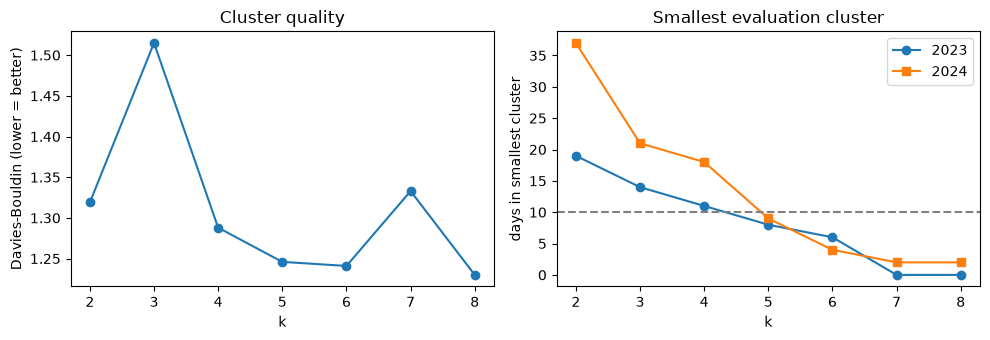

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(sweep.k, sweep.davies_bouldin, 'o-'); ax[0].set(xlabel='k', ylabel='Davies-Bouldin (lower = better)', title='Cluster quality')
ax[1].plot(sweep.k, sweep.smallest_2023, 'o-', label='2023'); ax[1].plot(sweep.k, sweep.smallest_2024, 's-', label='2024')
ax[1].axhline(10, ls='--', c='grey'); ax[1].set(xlabel='k', ylabel='days in smallest cluster', title='Smallest evaluation cluster'); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading Test A.** Apart from k=3, the index stays between about 1.23 and 1.33 for every k: it does not single out a best k.
The lowest value (k=8) comes with tiny clusters, and k=7 and k=8 leave a cluster with *zero* days in 2023, so error rates cannot be measured.
In the training period the smallest cluster holds 12.9% of days at k=4 (188 of 1,454) but only 6.2% at k=5 (90 days), 5.2% at k=6, 5.0% at k=7 and 1.6% at k=8 (`train_share` column). From k=5 upward the smallest evaluation cluster also has fewer than 10 days.

## A3. What each regime represents (Test B, k=4 versus k=5)

In [5]:
def centers(k):
    c = pd.read_csv(OUT / f'k{k}/regime_centers.csv').round(1)
    c.columns = ['cluster', 'train_days', 'days_2023', 'days_2024', 'prior_price', 'prior_sd',
                 'evening_minus_morning', 'temp', 'wind', 'cloud']
    return c.set_index('cluster')
print('k=4'); display(centers(4))
print('k=5'); display(centers(5))

k=4


,train_days,days_2023,days_2024,prior_price,prior_sd,evening_minus_morning,temp,wind,cloud
cluster,,,,,,,,,
0,487,129,131,65.9,18.8,-5.6,7.6,24.2,78.9
1,302,80,60,63.6,13.6,1.9,6.0,14.0,33.9
2,477,145,157,60.0,12.7,6.0,15.2,13.7,62.0
3,188,11,18,293.5,75.0,60.6,11.7,14.0,58.3


k=5


,train_days,days_2023,days_2024,prior_price,prior_sd,evening_minus_morning,temp,wind,cloud
cluster,,,,,,,,,
0,163,10,17,297.5,75.7,72.5,12.0,13.3,56.7
1,441,126,124,48.4,13.7,3.4,7.3,24.1,79.2
2,473,142,157,59.6,12.5,6.3,15.2,13.6,62.2
3,287,79,59,63.9,13.4,3.5,6.1,13.8,32.5
4,90,8,9,208.2,58.0,-57.5,9.7,21.6,69.9


**Reading Test B (k=4).** C0 windy and very cloudy, flat prices; C1 cold, clear, calm; C2 warm, mixed cloud;
C3 spike days (prior-day price about 293 EUR/MWh, large evening peak).
**k=5** keeps C0-C2 almost unchanged and splits the spike group in two: evening-peak spikes (mean 298, spread +72) and
windy morning-peak spikes (mean 208, spread -57). The extra regime has only 8 evaluation days in 2023 and 9 in 2024.

## A4. Choice of k and why

**Chosen: k = 4**, as in the starter.

1. *Quality does not discriminate.* Davies-Bouldin is 1.288 at k=4 versus 1.246 at k=5, a small gain, and every k except 3 lies in 1.23-1.33.
   The index measures compactness on training days only; it says nothing about whether regimes help explain forecast errors.
2. *Enough days per regime.* Using training days only: the smallest k=4 regime holds 188 of 1,454 days (12.9%); the smallest k=5 regime holds 90 (6.2%), about half as many, and it falls to 23 days (1.6%) at k=8. A thinner regime gives less reliable centers and, later, error rates resting on few days. Where to draw the line is a judgement: 90 days is still usable, so this favours k=4 without ruling k=5 out. The evaluation-year counts (11 and 18 days at k=4, 8 and 9 at k=5, and an empty regime in 2023 at k=7-8) point the same way but were not used to choose.
3. *Interpretable and distinct.* The four regimes have clearly different centers (windy-cloudy, cold-clear, warm, price spikes). Moving to k=5 only splits the spike regime and adds no distinct weather type.

Part C checks that the error finding is the same at k=4 and k=5, so it is not an artefact of this choice.

**Limits.** The choice of k is a judgement call, not a statistical optimum. k was chosen from training-period quality, sizes and interpretability;
the error tables in Part C are only a cross-check. 2023-2024 are development years and the spike regime has few days, so differences between regimes carry
substantial uncertainty (no interval has been computed). Archived input vintages are not fully verified.

# Part B · Random Forest

## B1. What the Random Forest looks like
The starter forest fitted on days before 2023 (the first evaluation month's training set).

In [6]:
x = pd.read_csv(ROOT / 'team/data/features.csv.gz', index_col='day', parse_dates=['day'])
y = pd.read_csv(ROOT / 'team/data/targets.csv.gz', index_col='day', parse_dates=['day'])
train = x.index < '2023-01-01'
forest = importlib.import_module('team.b-random-forest.model').build_model().fit(x[train], y[train])
nodes = np.array([t.tree_.node_count for t in forest.estimators_])
leaves = np.array([t.tree_.n_leaves for t in forest.estimators_])
depth = np.array([t.tree_.max_depth for t in forest.estimators_])
print(f'{train.sum()} training days, {x.shape[1]} input columns, {y.shape[1]} outputs, {len(forest.estimators_)} trees')
print(f'nodes per tree: mean {nodes.mean():.0f} (min {nodes.min()}, max {nodes.max()}); buckets per tree: mean {leaves.mean():.0f}; depth {depth.min()}-{depth.max()}')
print('\nTree 0, top two levels of questions:')
print(export_text(forest.estimators_[0], feature_names=list(x.columns), max_depth=2))
roots = pd.Series([x.columns[t.tree_.feature[0]] for t in forest.estimators_]).value_counts()
print('First question asked by each of the 100 trees:'); print(roots.head(6).to_string())

1454 training days, 604 input columns, 24 outputs, 100 trees
nodes per tree: mean 297 (min 283, max 313); buckets per tree: mean 149; depth 12-19

Tree 0, top two levels of questions:
|--- DE-LU_lag1_h22 <= 211.91
|   |--- NL_lag1_h23 <= 83.62
|   |   |--- DK1_lag1_h22 <= 37.20
|   |   |   |--- truncated branch of depth 12
|   |   |--- DK1_lag1_h22 >  37.20
|   |   |   |--- truncated branch of depth 14
|   |--- NL_lag1_h23 >  83.62
|   |   |--- DE-LU_lag1_h22 <= 109.42
|   |   |   |--- truncated branch of depth 7
|   |   |--- DE-LU_lag1_h22 >  109.42
|   |   |   |--- truncated branch of depth 10
|--- DE-LU_lag1_h22 >  211.91
|   |--- NL_lag1_h18 <= 399.84
|   |   |--- DK1_lag1_h21 <= 269.43
|   |   |   |--- truncated branch of depth 6
|   |   |--- DK1_lag1_h21 >  269.43
|   |   |   |--- truncated branch of depth 4
|   |--- NL_lag1_h18 >  399.84
|   |   |--- NL_lag1_h23 <= 475.21
|   |   |   |--- truncated branch of depth 6
|   |   |--- NL_lag1_h23 >  475.21
|   |   |   |--- truncated b

### What goes into the forest: the 604 input columns and the forest's settings
Each row is one delivery day, and each column is one number known at the forecast cutoff (10:00 on the day before). The forest predicts 24 numbers per day, the DK1 prices for each hour.
The next cell counts the columns by group and prints the settings of the forest that was just fitted.

In [7]:
groups = {'yesterday price curve, 5 zones (lag 1)': x.columns.str.contains('_lag1_'),
          'price curve 7 days ago, 5 zones (lag 7)': x.columns.str.contains('_lag7_'),
          'forecast weather for the target day (5 zones x 3 variables x 24 h)': x.columns.str.startswith('weather_'),
          'calendar (weekday and time of year, sine/cosine)': x.columns.str.contains('weekday_|year_')}
counts = pd.Series({name: int(mask.sum()) for name, mask in groups.items()})
assert counts.sum() == x.shape[1]                      # every column belongs to exactly one group
print(counts.to_string(), f'\n{"total":>70}  {counts.sum()}\n')
for name, mask in groups.items():
    print(f'example column - {name[:28]:<28}: {x.columns[mask][0]}')
params = forest.get_params()
print('\nForest settings:', {k: params[k] for k in ['n_estimators', 'bootstrap', 'max_features', 'min_samples_leaf', 'max_depth']})

yesterday price curve, 5 zones (lag 1)                                120
price curve 7 days ago, 5 zones (lag 7)                               120
forecast weather for the target day (5 zones x 3 variables x 24 h)    360
calendar (weekday and time of year, sine/cosine)                        4 
                                                                 total  604

example column - yesterday price curve, 5 zon: DK1_lag1_h0
example column - price curve 7 days ago, 5 zo: DK1_lag7_h0
example column - forecast weather for the tar: weather_DK1_temperature_2m_h0
example column - calendar (weekday and time o: weekday_sin

Forest settings: {'n_estimators': 100, 'bootstrap': True, 'max_features': 1.0, 'min_samples_leaf': 5, 'max_depth': None}


**How this forest uses the inputs**
- **100 trees (`n_estimators=100`).** Each tree trains on its own resample of the training days, drawn with replacement (`bootstrap=True`), so every tree sees a different version of the history.
- **All 604 columns at every question (`max_features=1.0`).** At each split a tree considers every column and keeps the best one. There is no random column selection in this forest,
  so the only randomness between trees is the resampling of days. Many columns are near copies (prices at neighbouring hours), which is why the same few columns open most trees (see the count of first questions below).
  The original Random Forest idea also draws a random subset of columns at each split (`max_features` below 1); that is a possible later experiment and is **not** tested here.
- **`min_samples_leaf`.** A tree stops splitting when a bucket would hold fewer than this many samples (a resampled day can appear more than once). The starter uses 5; B2 tests other values.
- **Prediction = averaging.** A new day falls into one bucket in each tree; the bucket's prediction is the average 24-hour price curve of its training days; the forest's forecast is the hour-by-hour average of its 100 trees' curves.
  This is regression, so values are averaged and no class is voted on.

## B2. Choosing `min_samples_leaf` (validation year 2022)

`min_samples_leaf` is the smallest number of past days a bucket at the bottom of a tree may contain.
Small values let trees memorise individual days; large values average more days and smooth the forecast.
Which is better can only be decided by comparing forecast errors, so the choice needs **scored predictions**.

**Protocol (fixed before looking at any result)**

```
2019 ─ 2021        2022                    2023 ─ 2024
 training    VALIDATION: choose leaf    FINAL: run once with the frozen choice
```
**Expanding window, monthly refit** (same as the shared benchmark): each month is predicted by a forest trained on *all days before that month*;
the start never moves (2019-01-08), the end advances one month at a time, and nothing is dropped.

| Month predicted | Trained on |
|---|---|
| Jan 2022 | 2019-01-08 to 2021-12-31 (exactly 2019-2021) |
| Dec 2022 | 2019-01-08 to 2022-11-30 |
| Jan 2024 | 2019-01-08 to 2023-12-31 |

So 2022 validation uses 2019-2021 for January and, for later months, also the earlier 2022 months. Selecting under the final protocol keeps the choice relevant to the 2023-2024 runs.

- **Round 1 (planned):** `min_samples_leaf` in {5 (starter), 10, 20}.
- **Round 2 (added after round 1):** {1, 2, 3}, added because the round 1 winner (5) was the smallest value tried, so the optimum might lie below it. All six settings are reported.
- Everything else in `model.py` is unchanged; one setting is varied at a time.
- **Selection rule, fixed in advance: lowest all-hour MAE in 2022 across all settings tried.** No 2023-2024 data are touched in this section.
- Predictions are always scored on days the forest has not seen; errors on training days would favour the most overfit setting.
- 2022 was the energy-crisis year, an unusual validation period; and trying six values on one year gives a small chance of picking a lucky one.

Results are cached in `results/team/rf_leaf_search/` (Git-ignored); uncached settings take several minutes.

In [8]:
sys.path.insert(0, str(ROOT / 'scripts'))
from team_benchmark_core import run_prepared                  # shared monthly walk-forward + metrics
from run_team_benchmark import load_snapshot, SNAPSHOT
import os
from joblib import Parallel, delayed

model_module = importlib.import_module('team.b-random-forest.model')
data = load_snapshot(SNAPSHOT)                                # features, targets, hourly prices

ROUND = {5: 'round 1', 10: 'round 1', 20: 'round 1', 1: 'round 2', 2: 'round 2', 3: 'round 2'}
LEAF_VALUES = tuple(ROUND)
VALIDATION = ('2022-01-01', '2023-01-01')                     # validation year; 2023-2024 untouched here
SEARCH = ROOT / 'results/team/rf_leaf_search'

def validate(leaf):
    dest = SEARCH / f'leaf{leaf}'
    if not (dest / 'metrics.csv').exists():                   # reuse an earlier run if present
        build = lambda: model_module.build_model().set_params(min_samples_leaf=leaf)
        run_prepared(f'rf_leaf{leaf}', build, *VALIDATION, *data, dest)

with contextlib.redirect_stdout(io.StringIO()):               # silence per-month progress lines
    Parallel(n_jobs=min(len(LEAF_VALUES), os.cpu_count()), prefer='threads')(delayed(validate)(leaf) for leaf in LEAF_VALUES)

In [9]:
rows = []
for leaf in LEAF_VALUES:
    m = pd.read_csv(SEARCH / f'leaf{leaf}/metrics.csv').iloc[0]
    fit = pd.read_csv(SEARCH / f'leaf{leaf}/timing.csv').fit_seconds.sum()
    rows.append(dict(round=ROUND[leaf], min_samples_leaf=leaf, mae=m.mae, rmse=m.rmse, hits_5pct=f'{int(m.hits_5pct)}/{int(m.eligible)}',
                     rate_5pct=m.rate_5pct, negative_mae=m.negative_mae, fit_seconds_total=fit))
search = pd.DataFrame(rows).sort_values(['round', 'min_samples_leaf'], ascending=[True, False]).round(3)
SELECTED = int(search.loc[search.mae.idxmin(), 'min_samples_leaf'])   # pre-specified rule: lowest 2022 MAE
print('Validation year 2022 (expanding monthly refit, 12 fits per setting; selection = lowest MAE of all six)')
display(search)
print('Selected min_samples_leaf =', SELECTED)

Validation year 2022 (expanding monthly refit, 12 fits per setting; selection = lowest MAE of all six)


,round,min_samples_leaf,mae,rmse,hits_5pct,rate_5pct,negative_mae,fit_seconds_total
2,round 1,20,64.300,93.157,1106/8351,0.132,87.189,143.596
1,round 1,10,58.483,86.231,1400/8351,0.168,79.606,171.573
0,round 1,5,55.149,80.556,1393/8351,0.167,76.093,200.888
5,round 2,3,54.126,78.567,1398/8351,0.167,75.059,235.096
4,round 2,2,53.491,77.570,1362/8351,0.163,75.949,253.743
3,round 2,1,53.640,77.604,1403/8351,0.168,75.559,287.119


Selected min_samples_leaf = 2


**Reading B2 (both rounds).** Over the six settings tried, 2022 MAE is 64.3 (leaf 20), 58.5 (10), 55.1 (5), 54.1 (3), 53.5 (2) and 53.6 (1):
error falls as the leaf shrinks, then flattens below 5. By the pre-specified rule (lowest 2022 MAE) the selected value is **2**, an improvement of
1.66 EUR/MWh (3.0%) over the starter's 5. RMSE follows the same order (77.6 vs 80.6).

Mixed signals: leaf 2 has a slightly *lower* ±5% hit count than leaf 5 (1362 vs 1393 of 8,351 eligible hours), and its negative-price MAE
(75.9) is about the same as leaf 5 (76.1). Leaves 1, 2 and 3 differ by under 0.7 EUR/MWh, so the exact choice among them is not reliable.

Interpretation: more averaging (a bigger leaf) hurt in the volatile 2022 year, plausibly because smoothing pulls forecasts toward typical prices and misses extremes.
Limits: one validation year (the energy-crisis year), six candidates tried on it, and no uncertainty interval on the differences. The choice is therefore frozen
and tested once on 2023-2024 in B4 (B3 shows the evaluation of the forest we keep).

## B3. Evaluation of the chosen forest on 2023-2024 (`min_samples_leaf` = 5)
The starter forest as shipped in `model.py`: 100 trees, bootstrap, all 604 columns considered at each split, `min_samples_leaf` = 5, expanding window with a monthly refit.
Every prediction comes from a forest trained only on earlier days. Frozen Ridge is shown for context (MAE from `team/RIDGE_BASELINE.md`, RMSE from Table I of the course report draft).
2023-2024 are development years, so this is an exploratory evaluation, not an independent confirmation.

In [10]:
BASELINE = ROOT / 'results/team/random_forest'    # starter forest (leaf 5) from the shared benchmark
ridge = pd.DataFrame({'model': 'Ridge (frozen)', 'year': [2023, 2024], 'hours': [8760, 8784], 'mae': [18.78, 18.34],
                      'rmse': [26.65, 29.52], 'hits_5pct': ['1575/7738', '1356/7620'], 'rate_5pct': [.2035, .1780],
                      'negative_hours': [np.nan, np.nan], 'negative_mae': [np.nan, np.nan]})

def summary(folder, name):
    m = pd.read_csv(folder / 'metrics.csv')
    return pd.DataFrame({'model': name, 'year': m.year, 'hours': m.hours, 'mae': m.mae, 'rmse': m.rmse,
                         'hits_5pct': m.hits_5pct.astype(int).astype(str) + '/' + m.eligible.astype(str), 'rate_5pct': m.rate_5pct,
                         'negative_hours': m.negative_hours, 'negative_mae': m.negative_mae})

chosen = summary(BASELINE, 'RF leaf=5 (chosen)')
timing = pd.read_csv(BASELINE / 'timing.csv')
print(f'{len(timing)} monthly fits: total fit {timing.fit_seconds.sum():.0f} s, total predict {timing.predict_seconds.sum():.1f} s; '
      f'training days per fit {timing.train_days.min()} to {timing.train_days.max()}')
pd.concat([chosen, ridge]).round(3).set_index(['year', 'model']).sort_index()

24 monthly fits: total fit 889 s, total predict 0.3 s; training days per fit 1454 to 2154


hours     mae    rmse  hits_5pct  rate_5pct  negative_hours  negative_mae
year model                                                                                        
2023 RF leaf=5 (chosen)   8760  21.002  30.498  1598/7738      0.207           281.0        48.232
     Ridge (frozen)       8760  18.780  26.650  1575/7738      0.204             NaN           NaN
2024 RF leaf=5 (chosen)   8784  18.982  31.555  1395/7620      0.183           375.0        29.525
     Ridge (frozen)       8784  18.340  29.520  1356/7620      0.178             NaN           NaN

**Reading B3.** The starter forest scores MAE 21.00 (2023) and 18.98 (2024) EUR/MWh, RMSE 30.50 and 31.56, and a ±5% hit rate of 20.7% (1598 of 7,738 eligible hours) and 18.3% (1395 of 7,620).
Negative-price hours (281 and 375) have a much larger MAE than average: 48.2 and 29.5.

Against frozen Ridge the picture is mixed: the forest has *higher* MAE (+2.22, 12%, in 2023; +0.64, 3.5%, in 2024) and higher RMSE (+3.85 and +2.04), but slightly *more* hours within ±5%
(+0.3 and +0.5 percentage points). One reading, not tested here, is that the forest is often close but misses by more when it misses, consistent with it being unable to predict beyond the price levels it has seen.

## B4. Sensitivity: the rule-selected leaf (2) versus the chosen leaf (5)
The selection rule fixed in B2 (lowest 2022 MAE) picks **`min_samples_leaf` = 2**. It is run once over 2023-2024 under the same protocol and compared with the chosen forest on identical hours.

**Decision: keep leaf = 5.** The gain from leaf 2 is under 1% in both years, the ±5% hit count is slightly lower, and the difference is probably within run-to-run noise (no interval has been computed).
Keeping the starter also leaves `model.py` unchanged, so the lead's benchmark reproduces these results. This departs from the pre-specified rule and was decided *after* seeing the 2023-2024 comparison below, so it is a documented judgement, not a pre-registered choice.

In [11]:
FINAL = ROOT / 'results/team/rf_final'            # rule-selected leaf, 2023-2024, run once
if not (FINAL / 'metrics.csv').exists():
    build = lambda: model_module.build_model().set_params(min_samples_leaf=SELECTED)
    with contextlib.redirect_stdout(io.StringIO()):
        run_prepared(f'rf_leaf{SELECTED}', build, '2023-01-01', '2025-01-01', *data, FINAL)
comparison = pd.concat([chosen, summary(FINAL, f'RF leaf={SELECTED} (rule-selected)')]).round(3)
same_hours = (pd.read_csv(FINAL / 'predictions.csv.gz', index_col=0).index
              .equals(pd.read_csv(BASELINE / 'predictions.csv.gz', index_col=0).index))
print('Identical evaluation hours for both forests:', same_hours)
for tag, folder in [('leaf 5', BASELINE), (f'leaf {SELECTED}', FINAL)]:
    print(f'{tag}: total fit time {pd.read_csv(folder / "timing.csv").fit_seconds.sum():.0f} s over 24 monthly fits')
comparison.set_index(['year', 'model']).sort_index()

Identical evaluation hours for both forests: True
leaf 5: total fit time 889 s over 24 monthly fits
leaf 2: total fit time 751 s over 24 monthly fits


hours     mae    rmse  hits_5pct  rate_5pct  negative_hours  negative_mae
year model                                                                                               
2023 RF leaf=2 (rule-selected)   8760  20.860  30.263  1593/7738      0.206             281        46.893
     RF leaf=5 (chosen)          8760  21.002  30.498  1598/7738      0.207             281        48.232
2024 RF leaf=2 (rule-selected)   8784  18.909  31.390  1383/7620      0.181             375        28.634
     RF leaf=5 (chosen)          8784  18.982  31.555  1395/7620      0.183             375        29.525

**Reading B4.** With `min_samples_leaf` = 2 instead of 5, 2023-2024 errors improve only slightly:

| | 2023 | 2024 |
|---|---|---|
| MAE | 21.00 to 20.86 (-0.14, 0.7%) | 18.98 to 18.91 (-0.07, 0.4%) |
| RMSE | 30.50 to 30.26 | 31.56 to 31.39 |
| Negative-price MAE | 48.2 to 46.9 | 29.5 to 28.6 |
| ±5% hits | 1598 to 1593 of 7,738 | 1395 to 1383 of 7,620 |

The 3% MAE gain seen in the 2022 validation year shrank to under 1% in 2023-2024, and the ±5% hit count is marginally *lower*, so the change is not better on every measure.
Differences this small are probably within run-to-run noise; no uncertainty interval has been computed, so the notebook does not claim an improvement.
Both forests remain behind the frozen Ridge baseline (MAE 18.78 and 18.34), by about 2.1 EUR/MWh in 2023 and 0.6 in 2024.

Timing: total fit time was 889 s (leaf 5) and 751 s (leaf 2), but these came from separate runs under different load, so they are not a like-for-like comparison.
2023-2024 are development years, so this is exploratory.

# Part C · Forecast error by regime
Combines Part A (regime labels) and Part B (forecast errors).

## C1. Forecast error by regime (Test C)
Uses the Random Forest hourly predictions from the shared benchmark. A *large error* is an absolute error above the
2023 90th percentile (same rule as C's Apriori analysis).

In [12]:
PRED = ROOT / 'results/team/random_forest/predictions.csv.gz'
assert PRED.exists(), 'Run first: python scripts/run_team_benchmark.py --model random_forest --data'
for k in (4, 5):
    print(f'--- k={k}')
    regime_errors.run(PRED, OUT / f'k{k}/regimes.csv', OUT / f'k{k}/regime_errors.csv')

--- k=4
Large-error threshold (2023 90th percentile): 47.17 EUR/MWh
              days  hours     mae    rmse  large_errors  large_error_rate
year cluster                                                             
2023 0         129   3097  21.590  30.910           289             0.093
     1          80   1919  19.956  26.871           183             0.095
     2         145   3480  20.726  31.469           360             0.103
     3          11    264  25.335  36.777            44             0.167
2024 0         131   3144  17.892  23.913           173             0.055
     1          60   1440  15.865  27.547            74             0.051
     2         157   3768  19.177  26.492           277             0.074
     3          18    432  35.611  86.223            58             0.134
--- k=5
Large-error threshold (2023 90th percentile): 47.17 EUR/MWh
              days  hours     mae    rmse  large_errors  large_error_rate
year cluster                                      

**Reading Test C.** At both k the evening-peak spike regime has the largest errors: large-error rate 16.7% / 13.4% at k=4
and 18.3% / 13.2% at k=5 (2023 / 2024), against roughly 5-10% elsewhere; its 2024 RMSE is about 85, three times the others.
The k=5 extra regime (windy morning-peak) is not worse than normal days (12.0% / 8.3%) but has only 8-9 days.
The spike clusters contain 11-18 days per year, so the evidence is suggestive, not conclusive.

**Robust finding.** The conclusion (the evening-peak spike regime is hardest) is the same at k=4 and k=5, so it does not depend on the choice of k.

## C2. Does the rule-selected leaf (2) help in the spike regime? (k=4)
Per-regime MAE and RMSE for the starter and the selected forest on the same days. Large-error *rates* are not compared here because `regime_errors.py`
sets the threshold from each model's own 2023 errors, so the two rates would use different thresholds.

In [13]:
for tag, folder in [('baseline', BASELINE), ('selected', FINAL)]:
    with contextlib.redirect_stdout(io.StringIO()):
        regime_errors.run(folder / 'predictions.csv.gz', OUT / 'k4/regimes.csv', OUT / f'k4/regime_errors_{tag}.csv')
b = pd.read_csv(OUT / 'k4/regime_errors_baseline.csv', index_col=['year', 'cluster'])
s = pd.read_csv(OUT / 'k4/regime_errors_selected.csv', index_col=['year', 'cluster'])
pd.DataFrame({'days': b.days, 'mae_leaf5': b.mae, f'mae_leaf{SELECTED}': s.mae,
              'rmse_leaf5': b.rmse, f'rmse_leaf{SELECTED}': s.rmse}).round(2)

days  mae_leaf5  mae_leaf2  rmse_leaf5  rmse_leaf2
year cluster                                                    
2023 0         129      21.59      21.63       30.91       30.85
     1          80      19.96      19.56       26.87       26.41
     2         145      20.73      20.53       31.47       31.16
     3          11      25.33      25.69       36.78       36.83
2024 0         131      17.89      18.06       23.91       23.97
     1          60      15.86      15.70       27.55       27.43
     2         157      19.18      18.97       26.49       26.26
     3          18      35.61      35.33       86.22       85.63

**Reading C2.** Changing the leaf from 5 to 2 does not change the picture by regime. Differences in MAE are within about 0.4 EUR/MWh in every regime and
move in both directions (for the spike regime, 25.33 to 25.69 in 2023 and 35.61 to 35.33 in 2024). The spike regime remains by far the hardest
(2024 RMSE about 86 against 24-27 elsewhere), so there is no evidence that the smaller leaf helps on spike days. Large-error rates are not compared
because the helper sets its threshold from each model's own errors. The spike regime has only 11 and 18 days, so these comparisons are imprecise.

# Part D · Interpretation

**Setup.** A Random Forest (100 trees; each tree trains on a resample of the days drawn with replacement; every split looks at all 604 inputs; `min_samples_leaf` = 5) forecasts the 24 hourly DK1 prices of the next day.
It is refit every month on all earlier days (expanding window) and scored on 2023-2024. K-means (k = 4) was fitted on the 1,454 days before 2023 on six daily descriptors (yesterday's DK1 price level, spread and evening-minus-morning shape, and forecast temperature, wind and cloud) and then frozen.

**The forest.** MAE is 21.00 and 18.98 EUR/MWh in 2023 and 2024, with ±5% hit rates of 20.7% (1598/7,738) and 18.3% (1395/7,620). It is behind frozen Ridge on MAE and RMSE in both years (by 12% and 3.5% on MAE) but slightly ahead on the ±5% hit rate, so neither model dominates.
Tuning `min_samples_leaf` on a 2022 validation year showed that larger buckets hurt (MAE 55.1 at leaf 5, 58.5 at 10, 64.3 at 20) and that very small ones barely help (53.5 at leaf 2). On 2023-2024 the leaf-2 forest improved MAE by only 0.7% and 0.4%, so the starter setting was kept.
The starter was therefore already close to the best of the settings tried; a single change to this one setting is not what limits the forest.

**The regimes (k = 4).** The four groups differ clearly in weather and in the price level of the previous day:
- **Regime 0**, windy and very cloudy (about 24 m/s forecast wind, 79% cloud), cheap and flat prices.
- **Regime 1**, cold, clear and calm (about 6 °C, 34% cloud).
- **Regime 2**, warm with mixed cloud (about 15 °C), typical prices.
- **Regime 3**, days that follow a very expensive, volatile day (previous-day mean about 293 EUR/MWh, with a large evening peak). It is rare: 188 of the 1,454 training days and only 11 (2023) and 18 (2024) evaluation days.

**Which regimes have larger errors.** Regimes 0-2 behave alike: large-error rates (absolute error above 47.17 EUR/MWh, the 2023 90th percentile) of 9-10% in 2023 and 5-7% in 2024, MAE 16-22. **Regime 3 is clearly the hardest:** large-error rates of 16.7% (2023) and 13.4% (2024), MAE 25.3 and 35.6, and in 2024 an RMSE of 86 against 24-28 for the other regimes.
The same ranking holds at k = 5 (Part C), so it does not depend on this choice of k. From 2023 to 2024 the ordinary regimes improve while regime 3 stays poor. A plausible explanation, not tested here, is that after an extreme price day the forecast relies on yesterday's extreme values and a forest, which averages past days, cannot reproduce spikes it has rarely seen.

**Why k = 4 and leaf = 5.** k = 4 keeps every regime reasonably large (smallest 12.9% of training days against 6.2% at k = 5) and interpretable, while the quality index barely changes across k (Part A4). Leaf = 5 is the starter and was not beaten materially (B2-B4).

**Limits.**
- 2023-2024 are development years that informed earlier experiments, so everything here is exploratory, not confirmation.
- No uncertainty intervals were computed; the spike regime has few days and the leaf comparison is probably within noise.
- The 2022 validation year was an unusual (energy-crisis) year, and six leaf values were tried on it.
- Weather and price vintages are only partly verified against the 10:00 cutoff.
- The Ridge comparison uses the team's frozen numbers, not a rerun in this notebook.
- `regime_errors.py` sets its large-error threshold from the 2023 errors of the model being analysed, so thresholds differ between models.

**Hand-off.** Aggregate tables are in `team/b-random-forest/summary/`. Two row-level files are *not* in the PR because the team keeps row-level outputs in the Git-ignored `results/team/` directory:
`results/team/random_forest/regimes.csv` (daily regime labels for the Apriori analysis) and `results/team/random_forest/predictions.csv.gz` (hourly forecasts for the ensemble). Send them through whatever route the lead specifies.

# Part E · Run record and exported tables

In [14]:
import json, os, platform, shutil, subprocess, sklearn
commit = subprocess.run(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
manifest = json.loads((ROOT / 'team/data/manifest.json').read_text())
record = {'base_commit': commit, 'note': 'notebook and regime_errors.py were uncommitted when run',
          'python': platform.python_version(), 'scikit_learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
          'machine': f'{platform.platform()} ({platform.machine()}, {os.cpu_count()} cores)',
          'data_snapshot_sha256': manifest['sha256'], 'feature_days': manifest['feature_days'],
          'training_period': 'days before 2023-01-01 (K-means fit; first forest fits)', 'validation_period': '2022 (leaf search)',
          'evaluation_period': '2023-01-01 to 2024-12-31 (development years)',
          'forest_settings': {k: params[k] for k in ['n_estimators', 'bootstrap', 'max_features', 'min_samples_leaf', 'max_depth', 'random_state']},
          'settings_tried_leaf': dict(ROUND), 'kmeans': {'k': 4, 'n_init': 20, 'random_state': 42}}
print(json.dumps(record, indent=2))

{
  "base_commit": "008e3a126c4ac27a043217f07bf8268e02df8f3a",
  "note": "notebook and regime_errors.py were uncommitted when run",
  "python": "3.12.4",
  "scikit_learn": "1.9.1",
  "pandas": "2.3.3",
  "numpy": "2.5.5",
  "machine": "macOS-26.6.2-arm64-arm-64bit (arm64, 11 cores)",
  "data_snapshot_sha256": {
    "features.csv.gz": "67449b849f3898e50bad3479ff47fade0941f7f440b273f7a61e6db8d4d0d074",
    "targets.csv.gz": "7484cc10b069b0116607b3e14d2b8e17afda94ec421557f9d1c341133af269a3",
    "hourly.csv.gz": "d4e2ac18937835cd479f824191607cf77b8d7bc8356d74db2517f666ef1dae70"
  },
  "feature_days": 2185,
  "training_period": "days before 2023-01-01 (K-means fit; first forest fits)",
  "validation_period": "2022 (leaf search)",
  "evaluation_period": "2023-01-01 to 2024-12-31 (development years)",
  "forest_settings": {
    "n_estimators": 100,
    "bootstrap": true,
    "max_features": 1.0,
    "min_samples_leaf": 5,
    "max_depth": null,
    "random_state": 42
  },
  "settings_tried_l

In [15]:
SUMMARY = ROOT / 'team/b-random-forest/summary'   # aggregate tables only; row-level files stay in the Git-ignored results/team/
SUMMARY.mkdir(exist_ok=True)
for name, table in {'k_sweep.csv': sweep, 'leaf_search_2022.csv': search, 'rf_leaf5_metrics_by_year.csv': chosen,
                    'rf_leaf5_vs_leaf2_2023_2024.csv': comparison}.items():
    table.to_csv(SUMMARY / name, index=False)
for src, name in [(BASELINE / 'regime_centers.csv', 'regime_centers_k4.csv'), (BASELINE / 'regime_diagnostics.csv', 'regime_diagnostics_k4.csv'),
                  (BASELINE / 'timing.csv', 'rf_leaf5_timing.csv'), (OUT / 'k4/regime_errors_baseline.csv', 'regime_errors_k4_leaf5.csv'),
                  (OUT / 'k5/regime_errors.csv', 'regime_errors_k5_leaf5.csv')]:
    shutil.copy(src, SUMMARY / name)
(SUMMARY / 'run_record.json').write_text(json.dumps(record, indent=2) + '\n')
print(*sorted(f.name for f in SUMMARY.iterdir()), sep='\n')

k_sweep.csv
leaf_search_2022.csv
regime_centers_k4.csv
regime_diagnostics_k4.csv
regime_errors_k4_leaf5.csv
regime_errors_k5_leaf5.csv
rf_leaf5_metrics_by_year.csv
rf_leaf5_timing.csv
rf_leaf5_vs_leaf2_2023_2024.csv
run_record.json
